# Mini-Challenge 2 — Aufgabe 1.3: Segmentierung, Morphologie, Objekteigenschaften

**Student:** Christof Weickhardt  
**Land:** Kanada  
**Semester:** FS26

**Strukturhinweis:** Die Aufgabe folgt dem Professoren-Template: Daten & Domäne, methodisches Design, technische Umsetzung, Evaluation sowie Analyse & Kommunikation. Segmentiert werden sichtbare Innenflächen der Fensterpaneele in einer Empress-Fassaden-ROI. Die primäre Bewertungsmetrik ist Masken-Dice; Objektanzahl, Fläche, Umfang, Exzentrizität und Skeletonisierung werden beschreibend ausgewertet.

## Tag 11 — Daten & Domäne

### Use Case — Anwendungsfall

Der Anwendungsfall ist die bildgestützte Kulturerbe-Dokumentation der Empress-Fassade in Victoria, Kanada; das Gebäude ist als [National Historic Site](https://www.pc.gc.ca/apps/dfhd/page_nhs_eng.aspx?id=96) dokumentiert. In diesem Kontext werden Fassadenbilder genutzt, um wiederholte Fensterstrukturen zu zählen und einfache Formeigenschaften nachvollziehbar zu beschreiben. Die wiederkehrenden Edwardian-Fensterachsen mit Chateau-Stilelementen sind Teil des im [Canadian Register of Historic Places](https://www.historicplaces.ca/en/rep-reg/place-lieu.aspx?id=7414) (Eintrag 7414) erfassten Erscheinungsbildes; reproduzierbare Paneelzählung und einfache Formstatistik unterstützen damit eine nachvollziehbare Vorannotation für spätere Zustandsvergleiche, ohne eine denkmalpflegerische Beurteilung zu ersetzen. Die Aufgabe ergänzt Aufgabe 1.2: Dort werden Linienkandidaten für Gesimse und Achsen betrachtet, hier werden ähnliche Paneel-Innenflächen als Objekte extrahiert.

### Problem Statement — technische Problemstellung

Diese Aufgabe untersucht die bildbasierte Abgrenzung ähnlicher Paneelobjekte in einer komplexen Fassaden-ROI. Reflexionen, Rahmen, Schatten und Fassadendekor können wie Paneelinnenflächen wirken oder echte Paneelanteile verdecken. Für Kulturerbe-Dokumentation ist das kritisch, weil die [kanadischen Standards and Guidelines](https://parks.canada.ca/culture/rclp-crhp/standards) auf nachvollziehbare Entscheidungen zielen und Objektzählung nur nützlich ist, wenn die zugrunde liegende Segmentierung transparent begrenzt ist.

### Experimental Objective — Untersuchungsziel

Das Ziel ist, sichtbare Paneel-Innenflächen als ähnliche Objekte reproduzierbar zu zählen und einfache Formeigenschaften nachvollziehbar zu beschreiben. Dabei soll eine Kandidatenebene entstehen, nicht eine automatische denkmalpflegerische Endentscheidung.

### Data Definition, Source, and Visualization — Daten, Quelle und Visualisierung

Das repräsentative 2D-Bild ist dieselbe eigene RGB-Aufnahme der Empress-Fassade wie in Aufgabe 1.2. Die ROI enthält mehrere Reihen ähnlicher, überwiegend bläulich-dunkler Fensterpaneel-Innenflächen mit geringer Überlappung. Ein Objekt ist hier eine sichtbare Paneel-Innenfläche; Steinornamente, Fensterrahmen, Säulen und Schattenbereiche ohne paneelartige Innenfläche zählen nicht als Objekt. Die Datenquelle ist geeignet, weil die Paneele visuell ähnlich, aber durch Reflexionen, Perspektive und Fassadendekor realistisch erschwert sind.

Environment
Python: 3.12.11
NumPy: 2.3.5
Pandas: 2.2.3
seaborn: 0.13.2
scikit-image: 0.26.0
SciPy: 1.17.0
Bildpfad: images/C0D2037D-3959-4F04-B6D2-936473639D34_1_105_c.jpeg
SHA-1: 2f8cd99686206324bc45bb14c2b663b14e447a04


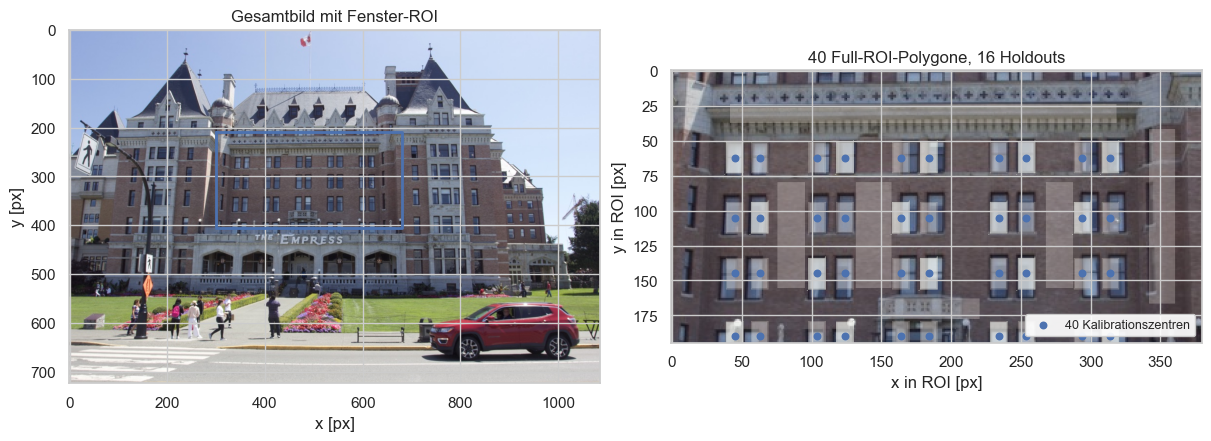

Holdout-Annotationspfad: annotations/empress_task3_holdout_polygons.json; SHA-1: fc6e13549c84a61d776b9c417ccfd2ae28f16337
Full-ROI-Annotationspfad: annotations/empress_task3_full_pane_polygons.json; SHA-1: 14f9e2e2109dc6ab67e629dfdc5caf971676ea6c
Abbildungsnotiz: Blau zeigt 40 Kalibrationsboxen für Separabilitäts- und Constraint-Begründung; Orange zeigt die 40 Full-ROI-Polygone der Hauptbewertung; Grün markiert das frühere Holdout-Subset als Audit-Kontext; Rot zeigt negative Kontrollflächen.


In [1]:
from pathlib import Path
import sys
import hashlib
import json

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi
import scipy
import skimage
from skimage import color, draw, measure, morphology, segmentation
from skimage.filters import threshold_otsu
from IPython.display import display, HTML

sns.set_theme(style="whitegrid", context="notebook")
PLOT_COLORS = sns.color_palette("deep")

IMAGE_CANDIDATES = [
    Path("images/C0D2037D-3959-4F04-B6D2-936473639D34_1_105_c.jpeg"),
    Path("notebooks/images/C0D2037D-3959-4F04-B6D2-936473639D34_1_105_c.jpeg"),
]
IMAGE_PATH = next((p for p in IMAGE_CANDIDATES if p.exists()), None)
if IMAGE_PATH is None:
    raise FileNotFoundError("Bildasset nicht im Repository gefunden: C0D2037D-...jpeg")

asset_sha1 = hashlib.sha1(IMAGE_PATH.read_bytes()).hexdigest()
print("Environment")
print(f"Python: {sys.version.split()[0]}")
print(f"NumPy: {np.__version__}")
print(f"Pandas: {pd.__version__}")
print(f"seaborn: {sns.__version__}")
print(f"scikit-image: {skimage.__version__}")
print(f"SciPy: {scipy.__version__}")
print(f"Bildpfad: {IMAGE_PATH}")
print(f"SHA-1: {asset_sha1}")

empress_image = np.asarray(Image.open(IMAGE_PATH).convert("RGB"))
window_roi = {"x1": 300, "y1": 210, "x2": 680, "y2": 405}
window_crop = empress_image[window_roi["y1"]:window_roi["y2"], window_roi["x1"]:window_roi["x2"]]

pane_x = [45, 63, 104, 124, 164, 184, 234, 254, 294, 314]
pane_y = [62, 105, 145, 190]
reference_pane_centers = np.array([[x, y] for y in pane_y for x in pane_x], dtype=int)
manual_reference_count = len(reference_pane_centers)


def reference_box_mask(shape: tuple[int, int], centers_xy: np.ndarray, half_width: int = 5, half_height: int = 10) -> np.ndarray:
    mask = np.zeros(shape, dtype=bool)
    for x, y in centers_xy:
        row0 = max(0, int(y) - half_height)
        row1 = min(shape[0], int(y) + half_height + 1)
        col0 = max(0, int(x) - half_width)
        col1 = min(shape[1], int(x) + half_width + 1)
        mask[row0:row1, col0:col1] = True
    return mask

reference_mask = reference_box_mask(window_crop.shape[:2], reference_pane_centers, half_width=5, half_height=10)

# Evaluation-only holdout: stratified hand polygons across rows/columns.
# These polygons are loaded from an auditable sidecar file and are not used for
# threshold, morphology, or object-constraint selection.
ANNOTATION_CANDIDATES = [
    Path("annotations/empress_task3_holdout_polygons.json"),
    Path("notebooks/annotations/empress_task3_holdout_polygons.json"),
]
ANNOTATION_PATH = next((p for p in ANNOTATION_CANDIDATES if p.exists()), None)
if ANNOTATION_PATH is None:
    raise FileNotFoundError("Holdout-Annotationsdatei nicht gefunden: empress_task3_holdout_polygons.json")
annotation_sha1 = hashlib.sha1(ANNOTATION_PATH.read_bytes()).hexdigest()
holdout_annotation = json.loads(ANNOTATION_PATH.read_text())
holdout_polygons = holdout_annotation["holdout_polygons"]
negative_control_polygons = holdout_annotation.get("negative_control_polygons", [])
holdout_polygon_vertices = [
    [tuple(point) for point in polygon["points"]]
    for polygon in holdout_polygons
]

FULL_ANNOTATION_CANDIDATES = [
    Path("annotations/empress_task3_full_pane_polygons.json"),
    Path("notebooks/annotations/empress_task3_full_pane_polygons.json"),
]
FULL_ANNOTATION_PATH = next((p for p in FULL_ANNOTATION_CANDIDATES if p.exists()), None)
if FULL_ANNOTATION_PATH is None:
    raise FileNotFoundError("Full-ROI-Annotationsdatei nicht gefunden: empress_task3_full_pane_polygons.json")
full_annotation_sha1 = hashlib.sha1(FULL_ANNOTATION_PATH.read_bytes()).hexdigest()
full_pane_annotation = json.loads(FULL_ANNOTATION_PATH.read_text())
full_pane_polygons = full_pane_annotation["pane_polygons"]
full_pane_polygon_vertices = [
    [tuple(point) for point in polygon["points"]]
    for polygon in full_pane_polygons
]
negative_control_vertices = [
    [tuple(point) for point in polygon["points"]]
    for polygon in negative_control_polygons
]
holdout_eval_window_vertices = []
for polygon in holdout_polygon_vertices:
    xs = [point[0] for point in polygon]
    ys = [point[1] for point in polygon]
    x_mid = int(round((min(xs) + max(xs)) / 2))
    y_mid = int(round((min(ys) + max(ys)) / 2))
    holdout_eval_window_vertices.append([
        (x_mid - 18, y_mid - 24),
        (x_mid + 18, y_mid - 24),
        (x_mid + 18, y_mid + 24),
        (x_mid - 18, y_mid + 24),
    ])


def polygon_mask(shape: tuple[int, int], polygons: list[list[tuple[int, int]]]) -> np.ndarray:
    mask = np.zeros(shape, dtype=bool)
    for polygon in polygons:
        vertices = np.asarray(polygon, dtype=float)
        rr, cc = draw.polygon(vertices[:, 1], vertices[:, 0], shape=shape)
        mask[rr, cc] = True
    return mask


holdout_polygon_mask = polygon_mask(window_crop.shape[:2], holdout_polygon_vertices)
holdout_eval_window_mask = polygon_mask(window_crop.shape[:2], holdout_eval_window_vertices)
full_pane_polygon_mask = polygon_mask(window_crop.shape[:2], full_pane_polygon_vertices)
negative_control_mask = polygon_mask(window_crop.shape[:2], negative_control_vertices) if negative_control_vertices else np.zeros(window_crop.shape[:2], dtype=bool)
holdout_reference_count = len(holdout_polygon_vertices)
full_reference_count = len(full_pane_polygon_vertices)
negative_control_count = len(negative_control_vertices)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
axes[0].imshow(empress_image)
axes[0].plot([window_roi["x1"], window_roi["x2"], window_roi["x2"], window_roi["x1"], window_roi["x1"]],
             [window_roi["y1"], window_roi["y1"], window_roi["y2"], window_roi["y2"], window_roi["y1"]], linewidth=2)
axes[0].set_title("Gesamtbild mit Fenster-ROI")
axes[0].set_xlabel("x [px]")
axes[0].set_ylabel("y [px]")
axes[1].imshow(window_crop)
axes[1].imshow(np.ma.masked_where(~reference_mask, reference_mask), cmap="Blues", alpha=0.22)
axes[1].imshow(np.ma.masked_where(~full_pane_polygon_mask, full_pane_polygon_mask), cmap="Oranges", alpha=0.24)
axes[1].imshow(np.ma.masked_where(~holdout_polygon_mask, holdout_polygon_mask), cmap="Greens", alpha=0.45)
axes[1].imshow(np.ma.masked_where(~negative_control_mask, negative_control_mask), cmap="Reds", alpha=0.25)
axes[1].scatter(reference_pane_centers[:, 0], reference_pane_centers[:, 1], s=22, color=PLOT_COLORS[0], label=f"{manual_reference_count} Kalibrationszentren")
axes[1].set_title(f"{full_reference_count} Full-ROI-Polygone, {holdout_reference_count} Holdouts")
axes[1].set_xlabel("x in ROI [px]")
axes[1].set_ylabel("y in ROI [px]")
axes[1].legend(loc="lower right", fontsize=9, framealpha=0.92)
plt.show()
print(f"Holdout-Annotationspfad: {ANNOTATION_PATH}; SHA-1: {annotation_sha1}")
print(f"Full-ROI-Annotationspfad: {FULL_ANNOTATION_PATH}; SHA-1: {full_annotation_sha1}")
print("Abbildungsnotiz: Blau zeigt 40 Kalibrationsboxen für Separabilitäts- und Constraint-Begründung; Orange zeigt die 40 Full-ROI-Polygone der Hauptbewertung; Grün markiert das frühere Holdout-Subset als Audit-Kontext; Rot zeigt negative Kontrollflächen.")

### Observations — Bildbeobachtung

Die Visualisierung zeigt vier sichtbare Paneelreihen in der Fenster-ROI. Die manuelle Box-Referenz mit 40 Zentren ist nicht-überlappend und markiert ähnliche, intensitätsbasiert trennbare Objekte (Paneel-Innenflächen). Die unterste Reihe (y=190) wird am Crop-Rand teilweise beschnitten, ist aber im Bild noch erkennbar.

## Tag 12 — Methodisches Design

### Theoretical Foundation and Method Choice — theoretische Grundlage und Methodenwahl

**Was:** Segmentiert werden Paneel-Innenflächen. **Wie:** Die Segmentierung nutzt eine globale Schwelle auf dem Skalarbild **Blue-Excess = B − R**, danach minimale Morphologie, zusammenhängende Komponenten und fixe Objektklassen-Constraints. **Warum:** Diese Reihenfolge trennt Farbevidenz von Objektplausibilität und macht jeden Annahmeschritt prüfbar.

Die manuellen Annotationen werden bewusst in getrennten Rollen verwendet: 40 einfache Kalibrationsboxen begründen Separabilität und Objektklassen-Constraints; eine separate Sidecar-Datei mit 40 Full-ROI-Paneelpolygonen dient in Tag 14 als primäre Bewertungsreferenz. Diese Full-ROI-Polygone werden nicht für Schwellenwahl, Morphologie oder Constraint-Grenzen verwendet. Die 16 früheren Holdout-Polygone und sechs negative Kontrollflächen bleiben nur als diagnostischer Audit-Kontext erhalten.

Die Wahl des Skalars **B − R** folgt einer einfachen optischen Plausibilität: typische Fensterglas-Reflexionen und durchscheinende Innenräume erscheinen relativ kühler (höherer Blauanteil, niedrigerer Rotanteil) als die warmere, terrakottafarbene Sandsteinfassade des Empress; B − R fasst diesen Farbkontrast in einer eindimensionalen Skala zusammen, ohne ein vollständiges Farbmodell zu unterstellen. Die unten gezeigte empirische Trennung (Median ≈ 29 in Paneelen vs. ≈ −3 in der übrigen ROI) bestätigt, dass diese eine Dimension hier ausreicht, ohne dass HSV- oder Lab-Transformationen nötig wären. Die Methode hängt jedoch ausdrücklich an der Bedingung warmsteiniger Fassade plus Tageslicht: Bei überzogenem Himmel mit kühler Globalbeleuchtung, andersfarbigen Steinen oder stark verspiegelten Glasflächen würde die Vorzeichenrichtung von $B-R$ kippen, weshalb die Methode pro Fassade und Aufnahme erneut zu validieren ist.

Otsu dient nur als datenbezogener Startpunkt für S0, nicht als nachträgliche Optimierungsentscheidung (Otsu, doi:10.1109/TSMC.1979.4310076). Danach entfernt Opening mit `disk(1)` einzelne Störpixel, Closing mit einem 3×3-Footprint verbindet kurze Unterbrechungen, und Hole-Filling schliesst kleine Löcher. Akzeptierte Objekte werden über zusammenhängende Komponenten extrahiert.

### Parameter Definition and Mathematical Specification — Parameterdefinition und mathematische Spezifikation

Das Skalarbild ist $B-R$ in 8-bit-Kanalwerten. S0 nutzt die Otsu-nahe Schwelle 12; S1 und S2 erhöhen die Schwelle kontrolliert auf 15 und 18. Die Morphologie nutzt kleine Footprints, damit Paneelformen nicht künstlich vergrössert oder verschmolzen werden. Gemessen werden Objektanzahl, Fläche $[px^2]$, Umfang $[px]$ und Exzentrizität $[-]$.

Die Schwellenstaffel 12/15/18 ist als kontrolliertes Sensitivitäts-Spezifitäts-Sweep um den Otsu-Wert herum gewählt: niedrigere Schwellen erhöhen den Recall (mehr Schatten- und Reflexionspaneele werden eingeschlossen), höhere Schwellen verbessern die Präzision (weniger Reflexions-/Rahmenpixel) und reduzieren Maskengrösse — Masken-Dice macht den Trade-off direkt vergleichbar. Höhere Schwellen verkleinern Paneelmasken systematisch; das ist beabsichtigt und in Tag 15 ausdrücklich diskutiert.

### Experimental Design for Next Days — Versuchsdesign für Umsetzung und Evaluation

Die Baseline ist S0. Systematisch variiert wird nur die Blue-Excess-Schwelle, während Closing und Objektklassen-Constraints konstant bleiben. Theoretisch wird erwartet, dass höhere Schwellen weniger Fassaden-/Reflexionsübertritt erzeugen, aber echte Paneelpixel stärker abschneiden. Dadurch entsteht ein direkter Trade-off zwischen kompakteren Masken und verfehlten Paneelanteilen.

| Konfiguration | Blue-excess-Schwelle | Closing | Zweck |
|---|---:|---:|---|
| S0 | 12 | 3×3 | Otsu-nahe Baseline |
| S1 | 15 | 3×3 | moderat strengere Paneeltrennung |
| S2 | 18 | 3×3 | strengere Kandidatenmaske gegen Stein-/Schatten-Maskenübertritt |

### Fixed Object-Class Constraints — fixierte Objektklassen-Constraints

| Constraint | Abgeleitet aus | fixer Wert | Warum konstant gehalten |
|---|---|---:|---|
| obere Zeilen ausschliessen | Crop-Trimm und obere Teilstrukturen | 22 px | entfernt nicht-paneelartige obere Struktur |
| Fläche | sichtbare Paneel-Innenflächenskala | 80–800 px² | toleriert Perspektive und Schwellen-Schrumpfung |
| Höhe | Paneel-Innenhöhe | 7–36 px | hält Objektgeometrie konstant |
| Breite | Paneel-Innenbreite | 4–32 px | hält Objektgeometrie konstant |
| Aspect Ratio | rechteckige Paneelform | 0.15–2.5 | verwirft Risse, Zierlinien und sehr lange Fragmente |

Die Constraints stammen nicht aus einem nachträglichen IQR-Fit der Ergebnisboxen und nicht aus den Full-ROI- oder Holdout-Polygonen. Sie werden direkt aus der groben Kalibrationsgeometrie abgeleitet: Die manuelle Referenzmaske nutzt 11×21-Innenflächenboxen, also nominell Fläche 11·21 = 231 px², Höhe 21 px und Breite 11 px. Die operativen Bereiche sind bewusst weit um diese Nominalwerte gewählt, damit perspektivische Verzerrung über vier Reihen, Schwellen-Schrumpfung bei strengerer Schwelle sowie partiell sichtbare Randpaneele weiterhin akzeptiert werden:

| Constraint | Nominal | gewählter Bereich | gewählter Bereich relativ zu Nominal |
|---|---:|---|---|
| Fläche | 231 px² | 80–800 px² | ca. 35 %–346 % |
| Höhe | 21 px | 7–36 px | ca. 33 %–171 % |
| Breite | 11 px | 4–32 px | ca. 36 %–291 % |
| Aspect | 0.52 | 0.15–2.5 | ca. 29 %–477 % |

Die deutlich asymmetrischen Obergrenzen (z. B. Fläche bis 346 %) reflektieren, dass im Crop einige sichtbare Paneele aufgrund der Aufnahmegeometrie und der Crop-Wahl deutlich breiter oder höher als die nominale 11×21-Box ausfallen können (besonders in der mittleren Bildtiefe); die Untergrenzen (~30 %) schliessen klar zu kleine Reflexions- oder Schattenfragmente aus. Die Aspect-Ratio-Bandbreite 0.15–2.5 deckt die nominale 11/21 ≈ 0.52 plus die perspektivisch flacheren Paneele der unteren Reihen ab.

### Skeletonization — Skeletonisierung

Für ein typisches Paneel wird ein Skeleton berechnet. Es dient als einfache Formrepräsentation: Bei sauber getrennten Paneelen bleibt das Skeleton kurz und zentral, während verschmolzene oder stark verzerrte Objekte längere, verzweigte Skeletons erzeugen können.

### Methodological Limitations and Risk Factors — methodische Limitationen und Risikofaktoren

Die Constraints sind feste Objektklassenannahmen und keine nachträgliche Optimierung auf den Dice-Wert. Dadurch bleibt der Vergleich zwischen S0/S1/S2 fair, auch wenn die finale Maske strenger ist als die rohe Schwellenmaske. Ein zweites Risiko ist die Referenz: Die Kalibrationsboxen approximieren Paneel-Innenflächen nur grob und werden deshalb nicht als Hauptmetrik verwendet. Tag 14 nutzt stattdessen die separate Full-ROI-Polygonreferenz; die alte 40-Box-Auswertung und das Holdout-Subset bleiben nur diagnostische Sensitivitäts- und Auditflächen.

### Empirical Separability Evidence — empirischer Trennungsnachweis

Die folgende Codezelle berechnet das B−R-Skalarbild, vergleicht die Verteilung in der Paneel-Referenzmaske gegen die übrige ROI und zeigt den Otsu-Schwellwert, der die Wahl der S0-Baseline (Schwelle 12) datenseitig motiviert.

,Bereich,Median blue-excess,IQR
0,Pane-Referenzmaske,29.0,33.0
1,übrige ROI,-3.0,15.0
2,Otsu-Schwellwert,12.0,NaN


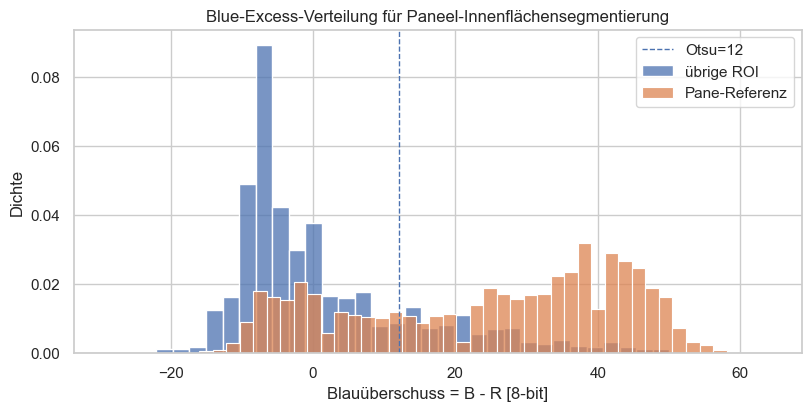

Methodischer Beleg: Paneele besitzen einen klar höheren Median-B−R als die übrige ROI; der Otsu-Schwellwert (12) liefert die datenbezogene S0-Baseline für Tag 13.


In [2]:
rgb_int = window_crop.astype(np.int16)
blue_excess_preview = rgb_int[:, :, 2] - rgb_int[:, :, 0]
pane_samples = blue_excess_preview[reference_mask]
background_samples = blue_excess_preview[~reference_mask]
otsu_threshold = int(threshold_otsu(blue_excess_preview))
separability_table = pd.DataFrame([
    {"Bereich": "Pane-Referenzmaske", "Median blue-excess": float(np.median(pane_samples)), "IQR": float(np.percentile(pane_samples, 75) - np.percentile(pane_samples, 25))},
    {"Bereich": "übrige ROI", "Median blue-excess": float(np.median(background_samples)), "IQR": float(np.percentile(background_samples, 75) - np.percentile(background_samples, 25))},
    {"Bereich": "Otsu-Schwellwert", "Median blue-excess": otsu_threshold, "IQR": np.nan},
])
display(separability_table.round(1))

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
sns.histplot(blue_excess_preview[~reference_mask].ravel(), bins=40, label="übrige ROI", ax=ax, stat="density", common_norm=False, color=PLOT_COLORS[0])
sns.histplot(blue_excess_preview[reference_mask].ravel(), bins=40, label="Pane-Referenz", ax=ax, stat="density", common_norm=False, color=PLOT_COLORS[1])
ax.axvline(otsu_threshold, linestyle="--", linewidth=1, label=f"Otsu={otsu_threshold}")
ax.set_title("Blue-Excess-Verteilung für Paneel-Innenflächensegmentierung")
ax.set_xlabel("Blauüberschuss = B - R [8-bit]")
ax.set_ylabel("Dichte")
ax.legend(loc="best")
plt.show()
print(f"Methodischer Beleg: Paneele besitzen einen klar höheren Median-B−R als die übrige ROI; der Otsu-Schwellwert ({otsu_threshold}) liefert die datenbezogene S0-Baseline für Tag 13.")

## Tag 13 — Implementation — technische Umsetzung

Die Pipeline wird exakt für S0–S2 umgesetzt. Visualisiert werden Skalarbild, Schwellenmaske, Morphologie, akzeptierte Komponenten und Skeleton. Die quantitative Bewertung folgt erst in Tag 14.

In [3]:
def segment_windows(
    rgb: np.ndarray,
    blue_excess_threshold: float,
    closing_size: int = 3,
    *,
    top_row_exclusion: int = 22,
    area_range: tuple[int, int] = (80, 800),
    height_range: tuple[int, int] = (7, 36),
    width_range: tuple[int, int] = (4, 32),
    aspect_range: tuple[float, float] = (0.15, 2.5),
) -> dict[str, object]:
    rgb_int = rgb.astype(np.int16)
    blue_excess = rgb_int[:, :, 2] - rgb_int[:, :, 0]
    initial_mask = blue_excess > blue_excess_threshold
    initial_mask[:top_row_exclusion, :] = False
    opened = morphology.opening(initial_mask, footprint=morphology.disk(1))
    closed = morphology.closing(opened, footprint=np.ones((closing_size, closing_size), dtype=bool))
    filled = ndi.binary_fill_holes(closed)
    labeled_initial = measure.label(filled)
    accepted = np.zeros(filled.shape, dtype=bool)
    for region in measure.regionprops(labeled_initial):
        min_row, min_col, max_row, max_col = region.bbox
        height = max_row - min_row
        width = max_col - min_col
        aspect_ratio = width / max(height, 1)
        keep = (
            area_range[0] <= region.area <= area_range[1]
            and height_range[0] <= height <= height_range[1]
            and width_range[0] <= width <= width_range[1]
            and aspect_range[0] <= aspect_ratio <= aspect_range[1]
        )
        if keep:
            accepted[labeled_initial == region.label] = True
    labeled = measure.label(accepted)
    properties = pd.DataFrame(measure.regionprops_table(
        labeled,
        properties=("label", "area", "perimeter", "eccentricity", "bbox"),
    ))
    return {
        "blue_excess": blue_excess,
        "initial_mask": initial_mask,
        "opened": opened,
        "closed": closed,
        "filled": filled,
        "refined_mask": accepted,
        "labeled": labeled,
        "properties": properties,
    }

segmentation_configs = [
    {"name": "S0 Otsu-nahe Referenz", "threshold": 12, "closing_size": 3},
    {"name": "S1 moderat streng", "threshold": 15, "closing_size": 3},
    {"name": "S2 streng", "threshold": 18, "closing_size": 3},
]

segmentation_results = {}
implementation_rows = []
for config in segmentation_configs:
    result = segment_windows(window_crop, blue_excess_threshold=config["threshold"], closing_size=config["closing_size"])
    segmentation_results[config["name"]] = result
    implementation_rows.append({
        "Konfiguration": config["name"],
        "threshold": config["threshold"],
        "closing": config["closing_size"],
        "Komponenten": int(result["labeled"].max()),
        "Maskenpixel akzeptiert": int(result["refined_mask"].sum()),
    })
implementation_table = pd.DataFrame(implementation_rows)
display(implementation_table)

,Konfiguration,threshold,closing,Komponenten,Maskenpixel akzeptiert
0,S0 Otsu-nahe Referenz,12,3,33,8920
1,S1 moderat streng,15,3,38,8665
2,S2 streng,18,3,37,8252


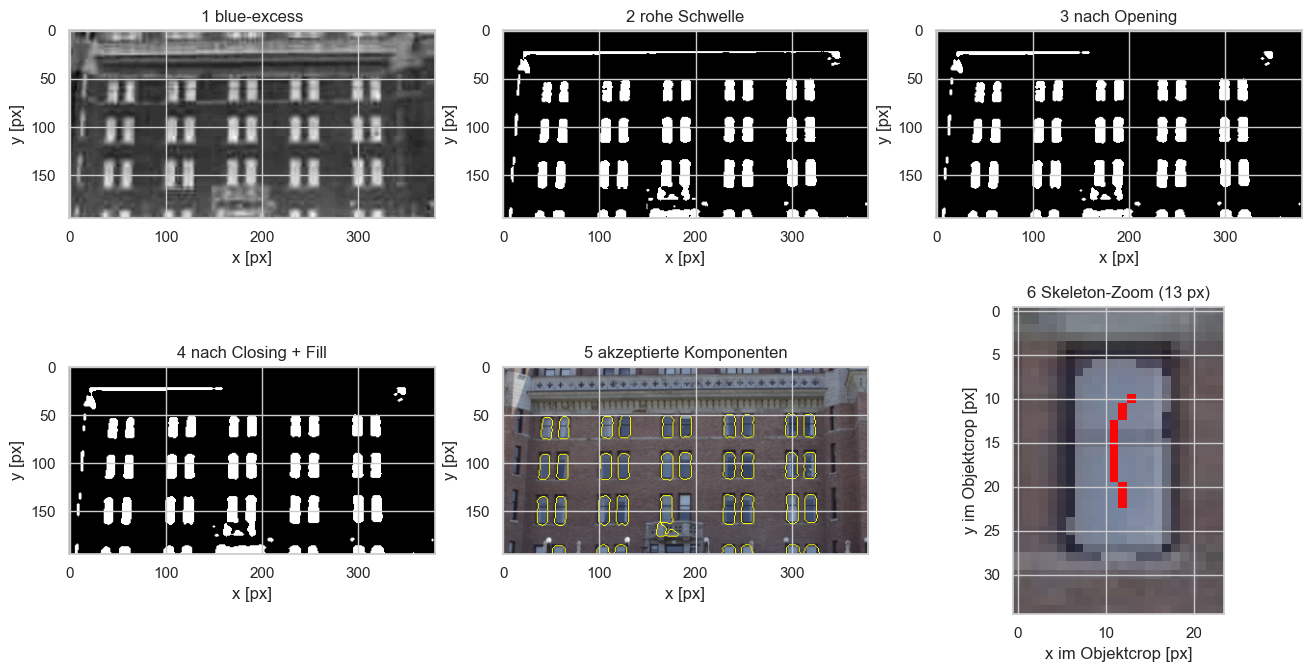

Abbildungsnotiz: Die Morphologie entfernt Einzelpixel und schliesst kleine Lücken; der Skeleton-Zoom zeigt die Formrepräsentation des typischen Paneels statt eines kaum sichtbaren Vollbild-Pixels.


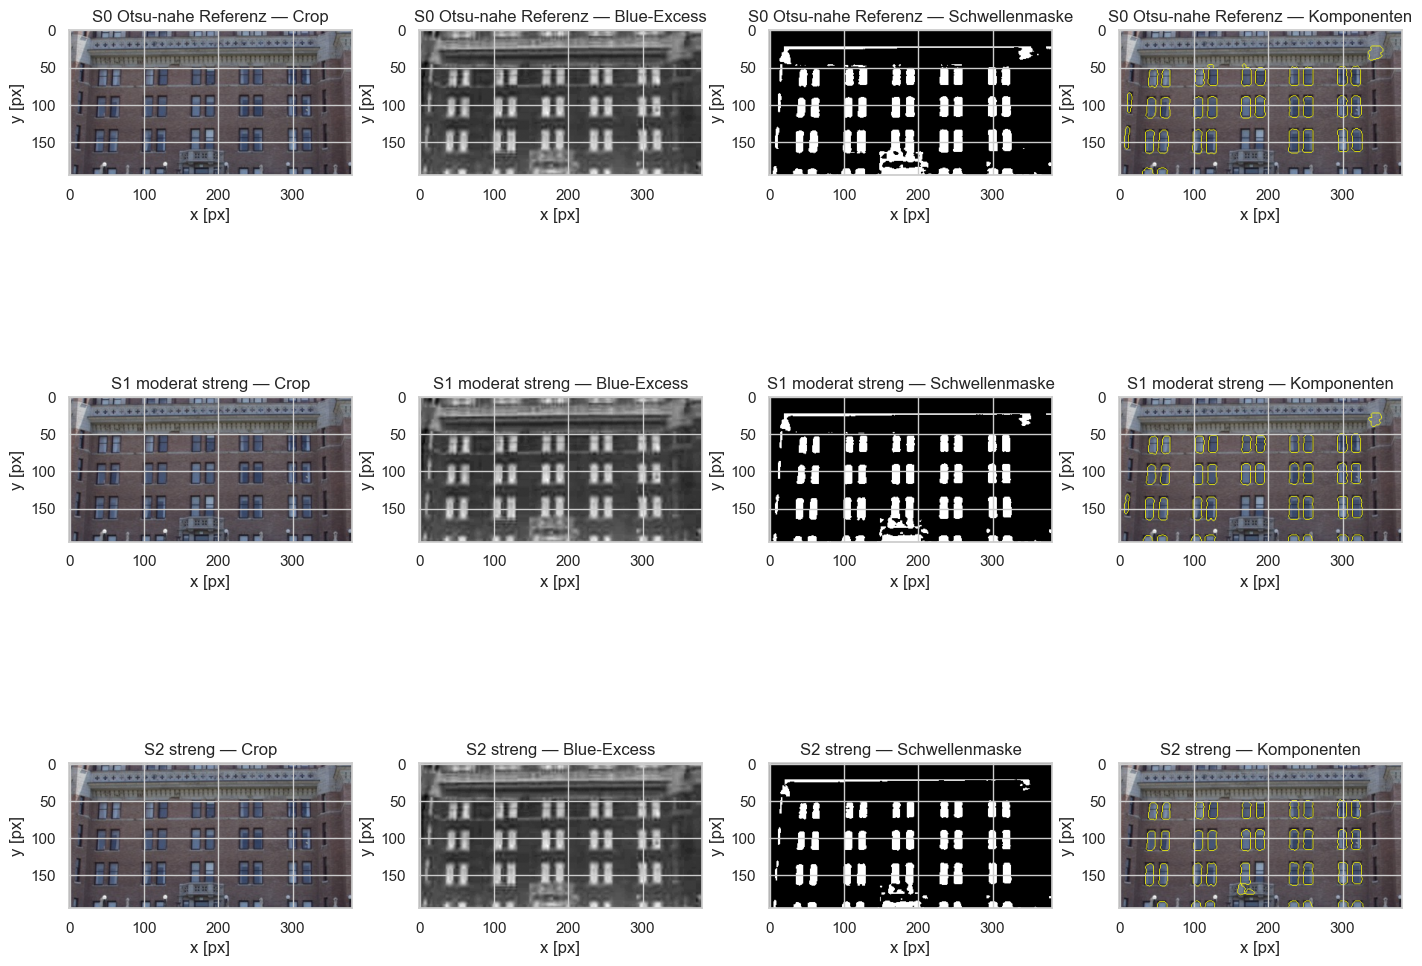

Abbildungsnotiz: Mit steigender Schwelle werden Masken kompakter; die Komponenten bleiben visuell als Paneel-Kandidaten erkennbar.


,Konfiguration,ausgewähltes Label,Skeleton-Pixel
0,S2 streng,4,13


In [4]:
# Morphologie-Streifen für S2: gleiche vordefinierte Pipeline, nur Zwischenstufen sichtbar gemacht.
s2_name = "S2 streng"
s2_result = segmentation_results[s2_name]

# Typisches Paneel: Komponente mit mittlerer Fläche in S2.
s2_props = s2_result["properties"]
median_area_index = (s2_props["area"] - s2_props["area"].median()).abs().idxmin()
selected_label = int(s2_props.loc[median_area_index, "label"])
selected_object = s2_result["labeled"] == selected_label
skeleton = morphology.skeletonize(selected_object)
skeleton_pixel_count = int(skeleton.sum())

ys, xs = np.where(selected_object)
pad = 6
r0 = max(0, int(ys.min()) - pad)
r1 = min(selected_object.shape[0], int(ys.max()) + pad + 1)
c0 = max(0, int(xs.min()) - pad)
c1 = min(selected_object.shape[1], int(xs.max()) + pad + 1)
object_crop = window_crop[r0:r1, c0:c1]
skeleton_crop = skeleton[r0:r1, c0:c1]
object_mask_crop = selected_object[r0:r1, c0:c1]

strip_items = [
    (s2_result["blue_excess"], "1 blue-excess", "gray", "global"),
    (s2_result["initial_mask"], "2 rohe Schwelle", "gray", "global"),
    (s2_result["opened"], "3 nach Opening", "gray", "global"),
    (s2_result["filled"], "4 nach Closing + Fill", "gray", "global"),
    (segmentation.mark_boundaries(window_crop, s2_result["labeled"], mode="outer"), "5 akzeptierte Komponenten", None, "global"),
    ((object_crop, object_mask_crop, skeleton_crop), f"6 Skeleton-Zoom ({skeleton_pixel_count} px)", None, "zoom"),
]
fig, axes = plt.subplots(2, 3, figsize=(13, 7), constrained_layout=True)
for ax, (arr, title, cmap, scope) in zip(axes.ravel(), strip_items):
    if scope == "zoom":
        crop_rgb, object_mask, skeleton_mask = arr
        ax.imshow(crop_rgb)
        ax.imshow(np.ma.masked_where(~object_mask, object_mask), cmap="Blues", alpha=0.28)
        ax.imshow(np.ma.masked_where(~skeleton_mask, skeleton_mask), cmap="autumn", alpha=0.95)
        ax.set_xlabel("x im Objektcrop [px]")
        ax.set_ylabel("y im Objektcrop [px]")
    else:
        ax.imshow(arr, cmap=cmap) if cmap else ax.imshow(arr)
        ax.set_xlabel("x [px]")
        ax.set_ylabel("y [px]")
    ax.set_title(title)
plt.show()
print("Abbildungsnotiz: Die Morphologie entfernt Einzelpixel und schliesst kleine Lücken; der Skeleton-Zoom zeigt die Formrepräsentation des typischen Paneels statt eines kaum sichtbaren Vollbild-Pixels.")

fig, axes = plt.subplots(3, 4, figsize=(14, 11), constrained_layout=True)
for row_index, config in enumerate(segmentation_configs):
    result = segmentation_results[config["name"]]
    panels = [
        (window_crop, "Crop", None),
        (result["blue_excess"], "Blue-Excess", "gray"),
        (result["initial_mask"], "Schwellenmaske", "gray"),
        (segmentation.mark_boundaries(window_crop, result["labeled"], mode="outer"), "Komponenten", None),
    ]
    for col, (arr, title, cmap) in enumerate(panels):
        axes[row_index, col].imshow(arr, cmap=cmap) if cmap else axes[row_index, col].imshow(arr)
        axes[row_index, col].set_title(f"{config['name']} — {title}")
        axes[row_index, col].set_xlabel("x [px]")
        axes[row_index, col].set_ylabel("y [px]")
plt.show()
print("Abbildungsnotiz: Mit steigender Schwelle werden Masken kompakter; die Komponenten bleiben visuell als Paneel-Kandidaten erkennbar.")

skeleton_table = pd.DataFrame([{"Konfiguration": s2_name, "ausgewähltes Label": selected_label, "Skeleton-Pixel": skeleton_pixel_count}])
display(skeleton_table)

## Tag 14 — Evaluation

### Evaluation Approach Definition — Definition des Evaluationsansatzes

Die einzige primäre Segmentierungsmetrik ist **Full-ROI-Polygon-Dice**. Bewertet wird gegen 40 versionierte Paneel-Innenflächen-Polygone aus der Sidecar-Datei `empress_task3_full_pane_polygons.json`. Anders als die frühere Holdout-Fensterwertung zählt diese Metrik die gesamte Fenster-ROI: Vorhersagepixel ausserhalb aller Paneelpolygone sind False Positives, verfehlte Polygonpixel sind False Negatives.

$$ Dice = \frac{2|M_{pred} \cap M_{poly,40}|}{|M_{pred}| + |M_{poly,40}|} $$

Diese Metrik bleibt genau ein Masken-Dice und passt zum Vorannotationsziel: Sie prüft, ob die Segmentierung alle wiederkehrenden Paneel-Innenflächen trifft, ohne zusätzliche Maskenanteile in Stein, Rahmen oder Reflexionsbereichen auszublenden. Objektanzahl und Objekteigenschaften werden zusätzlich beschreibend aggregiert, aber nicht als zweite primäre Segmentierungsmetrik verwendet.

Die Sidecar-Datei mit 16 Holdout-Polygonen bleibt als Audit-Kontext erhalten, nicht als Hauptmetrik. Zusätzlich enthält sie sechs negative Kontrollpolygone auf Steingesims, Backsteinzwischenräumen und Seitenstein. Diese Kontrollen werden nicht zur Konfigurationswahl und nicht für den Dice verwendet; sie prüfen nur, ob die Gewinner-Maske in klaren Nicht-Paneelbereichen False Positives erzeugt.

### Evaluation Comparison Execution — Vergleichsausführung

S0 dient als Baseline. Die Full-ROI-Dice-Änderung von S1 und S2 wird relativ zu S0 berichtet, und die Objektstatistiken werden für dieselben drei vordefinierten Konfigurationen aggregiert. Die frühere 40-Box-Dice-Auswertung bleibt nur im diagnostischen Anhang, damit die Hauptbewertung nicht dieselbe grobe Boxgeometrie nutzt, aus der die Constraints motiviert wurden.


,Konfiguration,Full-ROI-Polygon-Dice,Objektanzahl,Delta zu S0
0,S0 Otsu-nahe Referenz,0.589,33,0.000
1,S1 moderat streng,0.615,38,0.026
2,S2 streng,0.611,37,0.022


,Konfiguration,area_mean,area_std,perimeter_mean,perimeter_std,eccentricity_mean,eccentricity_std,area_std_delta_to_S0
0,S0 Otsu-nahe Referenz,270.30,71.91,68.08,9.75,0.89,0.07,0.00
1,S1 moderat streng,228.03,80.26,60.68,13.15,0.86,0.10,8.35
2,S2 streng,223.03,72.82,60.42,12.78,0.86,0.10,0.90


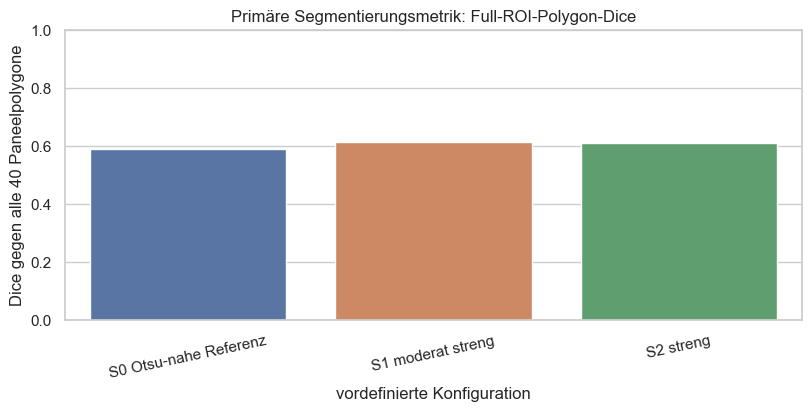

Plot-Hinweis: Der Balkenplot zeigt die Hauptmetrik je vordefinierter Konfiguration; S1 moderat streng liegt mit Full-ROI-Dice 0.615 vorn.


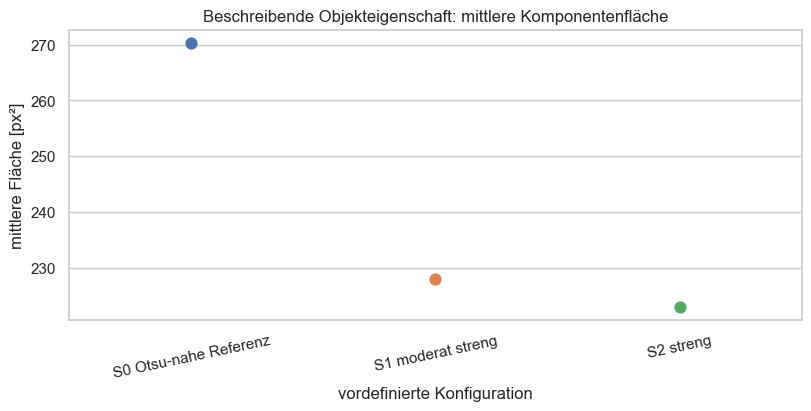

Plot-Hinweis: Der Punktplot zeigt die mittlere Komponentenfläche je vordefinierter Konfiguration; die fachliche Einordnung folgt in Tag 15.


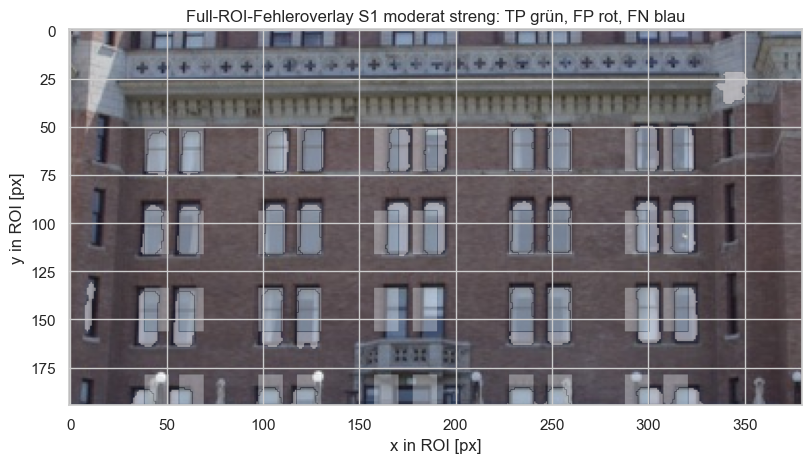

Plot-Hinweis: Das Fehleroverlay zählt die komplette ROI: Rot sind Vorhersagepixel ausserhalb aller 40 Paneelpolygone, Blau verfehlte Polygonanteile.


,Polygon,Reihe,Spalte,Polygonfläche,TP im Polygon,FN im Polygon,Paneel-Recall [%]
0,P01,R1,C1,299,205,94,68.6
1,P02,R1,C2,299,193,106,64.5
2,P03,R1,C3,299,164,135,54.8
3,P04,R1,C4,299,211,88,70.6
4,P05,R1,C5,299,110,189,36.8
5,P06,R1,C6,299,132,167,44.1
6,P07,R1,C7,299,242,57,80.9
7,P08,R1,C8,299,255,44,85.3
8,P09,R1,C9,299,158,141,52.8
9,P10,R1,C10,299,182,117,60.9


Full-ROI-Diagnostik: S1 moderat streng enthält 2607 vorhergesagte Pixel (30.1% der Vorhersagemaske) ausserhalb aller 40 Paneelpolygone. Diese Pixel sind jetzt Teil der Hauptmetrik und zählen als False Positives.


,Konfiguration,Negativkontrollfläche,FP Pixel in Negativkontrollen,FP-Rate Negativkontrollen [%],FP-Anteil an Gesamtmaske [%]
0,S0 Otsu-nahe Referenz,12334,0,0.00,0.00
1,S1 moderat streng,12334,0,0.00,0.00
2,S2 streng,12334,139,1.13,1.68


,Negativpolygon,Bereich,Fläche,FP Pixel,FP-Rate [%]
0,N01,oberes Steingesims,3878,0,0.0
1,N02,linker Backsteinzwischenraum,1520,0,0.0
2,N03,mittlerer Backsteinzwischenraum,1976,0,0.0
3,N04,rechter Backsteinzwischenraum,1520,0,0.0
4,N05,unteres Steinelement,1065,0,0.0
5,N06,rechter heller Steinrand,2375,0,0.0


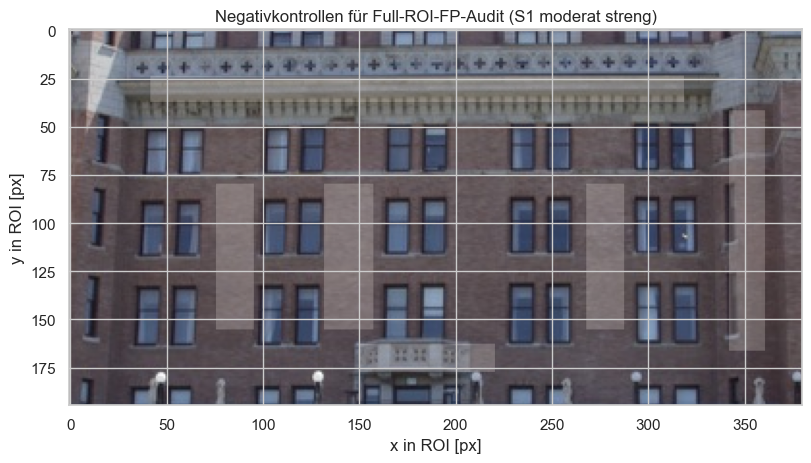

Full-ROI-Negativkontrolle: S1 moderat streng markiert 0 von 12334 Pixeln in den sechs negativen Kontrollpolygonen. Das entlastet die klaren Nicht-Paneelbereiche, ersetzt aber keine vollständige Full-ROI-Annotation.


In [5]:
def dice_score(pred_mask: np.ndarray, ref_mask: np.ndarray) -> float:
    denom = int(pred_mask.sum() + ref_mask.sum())
    return 1.0 if denom == 0 else float(2 * np.logical_and(pred_mask, ref_mask).sum() / denom)


def pixel_error_counts(pred_mask: np.ndarray, ref_mask: np.ndarray) -> dict[str, int]:
    return {
        "TP Pixel": int(np.logical_and(pred_mask, ref_mask).sum()),
        "FP Pixel": int(np.logical_and(pred_mask, ~ref_mask).sum()),
        "FN Pixel": int(np.logical_and(~pred_mask, ref_mask).sum()),
    }


def full_roi_dice(pred_mask: np.ndarray) -> float:
    return dice_score(pred_mask, full_pane_polygon_mask)


def holdout_dice(pred_mask: np.ndarray) -> float:
    # Diagnostic subset only; the primary metric below scores the full ROI.
    return dice_score(pred_mask & holdout_eval_window_mask, holdout_polygon_mask)


evaluation_rows = []
for config in segmentation_configs:
    name = config["name"]
    pred = segmentation_results[name]["refined_mask"]
    evaluation_rows.append({
        "Konfiguration": name,
        "Full-ROI-Polygon-Dice": full_roi_dice(pred),
        "Objektanzahl": int(segmentation_results[name]["labeled"].max()),
        **pixel_error_counts(pred, full_pane_polygon_mask),
    })
evaluation_table = pd.DataFrame(evaluation_rows)
baseline_dice = evaluation_table.loc[0, "Full-ROI-Polygon-Dice"]
evaluation_table["Delta zu S0"] = evaluation_table["Full-ROI-Polygon-Dice"] - baseline_dice
primary_segmentation_table = evaluation_table[["Konfiguration", "Full-ROI-Polygon-Dice", "Objektanzahl", "Delta zu S0"]]
display(primary_segmentation_table.round({"Full-ROI-Polygon-Dice": 3, "Delta zu S0": 3}))

property_tables = []
for config in segmentation_configs:
    props = segmentation_results[config["name"]]["properties"].copy()
    props.insert(0, "Konfiguration", config["name"])
    property_tables.append(props)
all_properties = pd.concat(property_tables, ignore_index=True)
property_summary = all_properties.groupby("Konfiguration").agg(
    area_mean=("area", "mean"),
    area_std=("area", "std"),
    perimeter_mean=("perimeter", "mean"),
    perimeter_std=("perimeter", "std"),
    eccentricity_mean=("eccentricity", "mean"),
    eccentricity_std=("eccentricity", "std"),
).reset_index()
property_summary["area_std_delta_to_S0"] = property_summary["area_std"] - property_summary.loc[0, "area_std"]
display(property_summary.round(2))

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
sns.barplot(data=evaluation_table, x="Konfiguration", y="Full-ROI-Polygon-Dice", hue="Konfiguration", dodge=False, legend=False, ax=ax)
ax.set_ylim(0, 1)
ax.set_title("Primäre Segmentierungsmetrik: Full-ROI-Polygon-Dice")
ax.set_xlabel("vordefinierte Konfiguration")
ax.set_ylabel("Dice gegen alle 40 Paneelpolygone")
ax.tick_params(axis='x', rotation=12)
plt.show()
best_name = evaluation_table.loc[evaluation_table["Full-ROI-Polygon-Dice"].idxmax(), "Konfiguration"]
best_value = evaluation_table["Full-ROI-Polygon-Dice"].max()
print(f"Plot-Hinweis: Der Balkenplot zeigt die Hauptmetrik je vordefinierter Konfiguration; {best_name} liegt mit Full-ROI-Dice {best_value:.3f} vorn.")

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
sns.pointplot(data=property_summary, x="Konfiguration", y="area_mean", hue="Konfiguration", dodge=False, legend=False, ax=ax)
ax.set_title("Beschreibende Objekteigenschaft: mittlere Komponentenfläche")
ax.set_xlabel("vordefinierte Konfiguration")
ax.set_ylabel("mittlere Fläche [px²]")
ax.tick_params(axis='x', rotation=12)
plt.show()
print("Plot-Hinweis: Der Punktplot zeigt die mittlere Komponentenfläche je vordefinierter Konfiguration; die fachliche Einordnung folgt in Tag 15.")

best_pred = segmentation_results[best_name]["refined_mask"]
tp = best_pred & full_pane_polygon_mask
fp = best_pred & ~full_pane_polygon_mask
fn = ~best_pred & full_pane_polygon_mask
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
ax.imshow(window_crop)
ax.imshow(np.ma.masked_where(~tp, tp), cmap="Greens", alpha=0.35)
ax.imshow(np.ma.masked_where(~fp, fp), cmap="Reds", alpha=0.45)
ax.imshow(np.ma.masked_where(~fn, fn), cmap="Blues", alpha=0.35)
ax.set_title(f"Full-ROI-Fehleroverlay {best_name}: TP grün, FP rot, FN blau")
ax.set_xlabel("x in ROI [px]")
ax.set_ylabel("y in ROI [px]")
plt.show()
print("Plot-Hinweis: Das Fehleroverlay zählt die komplette ROI: Rot sind Vorhersagepixel ausserhalb aller 40 Paneelpolygone, Blau verfehlte Polygonanteile.")


# Diagnostischer Audit: per-polygon Trefferzerlegung der gleichen Full-ROI-Hauptmetrik.
# Die Hauptmetrik bleibt der globale Full-ROI-Dice; diese Tabelle zeigt, welche Paneele getroffen oder verfehlt werden.
winner_pred_full = segmentation_results[best_name]["refined_mask"]
polygon_audit_rows = []
for polygon_spec, polygon_vertices in zip(full_pane_polygons, full_pane_polygon_vertices):
    polygon_ref = polygon_mask(window_crop.shape[:2], [polygon_vertices])
    tp_polygon = int((winner_pred_full & polygon_ref).sum())
    fn_polygon = int((~winner_pred_full & polygon_ref).sum())
    polygon_area = int(polygon_ref.sum())
    polygon_audit_rows.append({
        "Polygon": polygon_spec["id"],
        "Reihe": polygon_spec["row"],
        "Spalte": polygon_spec["column"],
        "Polygonfläche": polygon_area,
        "TP im Polygon": tp_polygon,
        "FN im Polygon": fn_polygon,
        "Paneel-Recall [%]": 100.0 * tp_polygon / max(polygon_area, 1),
    })
polygon_audit_table = pd.DataFrame(polygon_audit_rows)
display(polygon_audit_table.round({"Paneel-Recall [%]": 1}))

outside_full_ref_pred = winner_pred_full & ~full_pane_polygon_mask
outside_full_ref_pixels = int(outside_full_ref_pred.sum())
outside_full_ref_share = 100.0 * outside_full_ref_pixels / max(int(winner_pred_full.sum()), 1)
print(
    f"Full-ROI-Diagnostik: {best_name} enthält {outside_full_ref_pixels} vorhergesagte Pixel "
    f"({outside_full_ref_share:.1f}% der Vorhersagemaske) ausserhalb aller 40 Paneelpolygone. "
    "Diese Pixel sind jetzt Teil der Hauptmetrik und zählen als False Positives."
)


# Diagnostischer Full-ROI-False-Positive-Audit: negative Kontrollpolygone aus der Sidecar-Datei.
negative_control_rows = []
negative_area = int(negative_control_mask.sum())
for config in segmentation_configs:
    name = config["name"]
    pred = segmentation_results[name]["refined_mask"]
    negative_fp = int((pred & negative_control_mask).sum())
    negative_control_rows.append({
        "Konfiguration": name,
        "Negativkontrollfläche": negative_area,
        "FP Pixel in Negativkontrollen": negative_fp,
        "FP-Rate Negativkontrollen [%]": 100.0 * negative_fp / max(negative_area, 1),
        "FP-Anteil an Gesamtmaske [%]": 100.0 * negative_fp / max(int(pred.sum()), 1),
    })
negative_control_table = pd.DataFrame(negative_control_rows)
display(negative_control_table.round({
    "FP-Rate Negativkontrollen [%]": 2,
    "FP-Anteil an Gesamtmaske [%]": 2,
}))

negative_polygon_rows = []
for polygon_spec, polygon_vertices in zip(negative_control_polygons, negative_control_vertices):
    polygon_ref = polygon_mask(window_crop.shape[:2], [polygon_vertices])
    fp_pixels = int((winner_pred_full & polygon_ref).sum())
    area = int(polygon_ref.sum())
    negative_polygon_rows.append({
        "Negativpolygon": polygon_spec["id"],
        "Bereich": polygon_spec["label"],
        "Fläche": area,
        "FP Pixel": fp_pixels,
        "FP-Rate [%]": 100.0 * fp_pixels / max(area, 1),
    })
negative_polygon_audit_table = pd.DataFrame(negative_polygon_rows)
display(negative_polygon_audit_table.round({"FP-Rate [%]": 2}))

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
ax.imshow(window_crop)
ax.imshow(np.ma.masked_where(~negative_control_mask, negative_control_mask), cmap="Reds", alpha=0.22)
negative_fp_best = winner_pred_full & negative_control_mask
ax.imshow(np.ma.masked_where(~negative_fp_best, negative_fp_best), cmap="Purples", alpha=0.55)
ax.set_title(f"Negativkontrollen für Full-ROI-FP-Audit ({best_name})")
ax.set_xlabel("x in ROI [px]")
ax.set_ylabel("y in ROI [px]")
plt.show()
print(
    f"Full-ROI-Negativkontrolle: {best_name} markiert {int(negative_fp_best.sum())} von {negative_area} "
    "Pixeln in den sechs negativen Kontrollpolygonen. Das entlastet die klaren Nicht-Paneelbereiche, "
    "ersetzt aber keine vollständige Full-ROI-Annotation."
)


## Tag 15 — Analyse & Kommunikation, Schlussreflexion und Revisionen

### Observations — Beobachtung

S0 erreicht Full-ROI-Polygon-Dice 0.589, S1 0.615 und S2 0.611 gegen alle 40 Paneelpolygone. S1 liegt damit +0.026 über S0 und nur +0.004 über S2. Die Objektanzahl beträgt 33, 38, 37 bei 40 annotierten Paneelen. Die mittlere Komponentenfläche fällt von 270.3 px² (S0) auf 228.0 px² (S1) und 223.0 px² (S2). Für S1 liegen 2,607 Vorhersagepixel ausserhalb aller Paneelpolygone; sie zählen jetzt als False Positives in der Hauptmetrik.

### Interpretation — Deutung

S1 ist knapp am stärksten, weil die moderat strengere Schwelle helle Stein- und Reflexionsbereiche reduziert, ohne die Paneelinnenflächen so stark abzuschneiden wie S2. Der kleine Abstand zu S2 zeigt aber, dass die Entscheidung praktisch nicht robust genug für eine autonome Inventarisierung ist. Die Full-ROI-Bewertung ist strenger als die frühere Holdout-Fensterwertung, weil keine Vorhersagepixel ausserhalb der lokalen Fenster ausgeblendet werden.

### Discussion and Critical Reflection — Diskussion und kritische Reflexion

Die Pipeline ist als Vorannotation für menschliche Sichtprüfung brauchbar, nicht als fertiges Fassadeninventar. Ihre Stärke ist die transparente, reproduzierbare Trennung ähnlicher Paneelstrukturen; ihre Grenze ist die Empfindlichkeit gegenüber Beleuchtung, verdeckten Paneelen und einer manuell gesetzten Polygonreferenz. Für belastbare Kulturerbe-Dokumentation wären mehrere Bilder und unabhängig erstellte Polygonannotationen nötig.

**Revision note:** Die Hauptbewertung nutzt nun Full-ROI-Polygon-Dice aus einer versionierten JSON-Sidecar-Datei statt einer lokalen Holdout-Fensterwertung. Dadurch zählen Vorhersagen ausserhalb der Paneelpolygone als False Positives in der primären Metrik.


## Diagnostischer Anhang T3 — Pipeline- und Referenzsensitivität (nicht Teil der Hauptbewertung)

Dieser Anhang prüft zwei Robustheitsfragen ausserhalb der offiziellen Tag-14-Hauptbewertung: erstens, wie die offiziell gewählte S1-Pipeline innerhalb derselben ROI-Zeilenmaske durch Morphologie und Shape-Filter verändert wird; zweitens, wie empfindlich die Segmentierungsentscheidung gegenüber kleinen Lage- und Grössenannahmen der alten manuellen Box-Referenz ist.


,Pipeline-Stufe,Full-ROI-Polygon-Dice,Maskenpixel
0,Schwelle (Top-row-Maske),0.584,11641
1,Opening,0.595,11165
2,Closing+Fill,0.596,11260
3,CC ohne Shape-Filter,0.596,11260
4,CC mit Shape-Filter,0.615,8665


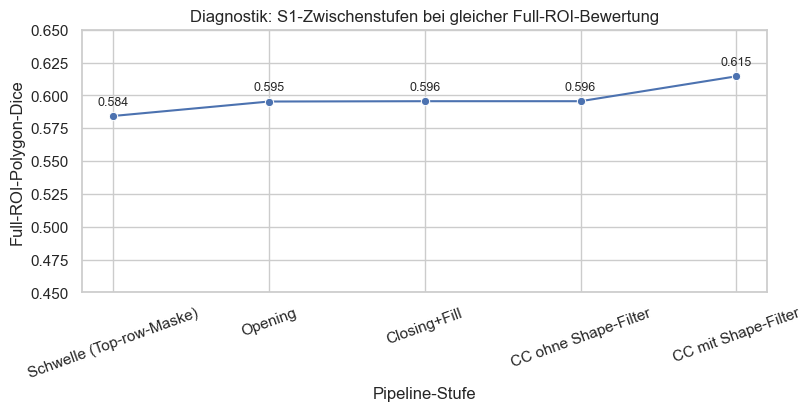

Diagnostische Lesart: Die Ablation ist kein vollständig constraint-freier Gegenentwurf; die Top-row-Maske und Full-ROI-Polygonreferenz bleiben konstant, damit nur Morphologie und Shape-Filter innerhalb derselben ROI-Annahme sichtbar werden.


,Konfiguration,Dice_Mittel,Dice_Min,Dice_Max,Dice_Spannweite
0,S0 Otsu-nahe Referenz,0.537,0.471,0.575,0.104
1,S1 moderat streng,0.572,0.513,0.607,0.094
2,S2 streng,0.574,0.507,0.620,0.113


Konfiguration,S0 Otsu-nahe Referenz,S1 moderat streng,S2 streng
Referenzvariante,,,
2 px links,0.481,0.513,0.507
2 px oben,0.534,0.568,0.569
2 px rechts,0.572,0.607,0.620
2 px unten,0.562,0.597,0.602
Basis 11x21,0.565,0.602,0.606
grösser 15x25,0.575,0.594,0.589
kleiner 9x17,0.471,0.518,0.527


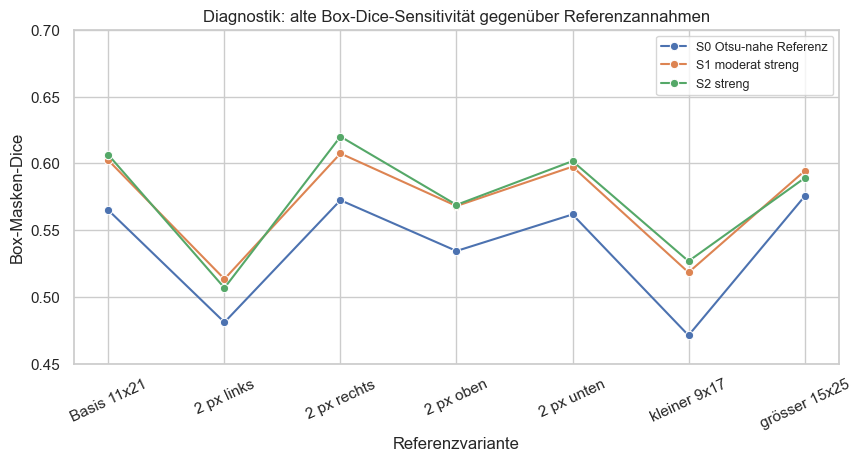

Diagnostische Lesart: Die alte 40-Box-Auswertung überschätzt nicht einfach eine einzelne Konfiguration; S1 und S2 bleiben eng beieinander, und kleine Boxverschiebungen können die Reihenfolge drehen. Darum nutzt die Hauptbewertung nun Full-ROI-Polygone statt die grobe Boxgeometrie.


In [6]:
# Diagnostischer Anhang T3a — S1-Pipeline-Ablation; gleiche Full-ROI-Dice-Metrik, nicht Teil der Tag-14-Hauptbewertung.
s1_name = "S1 moderat streng"
s1_result = segmentation_results[s1_name]
s1_no_shape_filter = segment_windows(
    window_crop,
    blue_excess_threshold=15,
    closing_size=3,
    area_range=(0, 1_000_000),
    height_range=(0, 1_000_000),
    width_range=(0, 1_000_000),
    aspect_range=(0.0, 1_000.0),
)["refined_mask"]

stage_rows = [
    {"Pipeline-Stufe": "Schwelle (Top-row-Maske)", "Full-ROI-Polygon-Dice": full_roi_dice(s1_result["initial_mask"]), "Maskenpixel": int(s1_result["initial_mask"].sum())},
    {"Pipeline-Stufe": "Opening", "Full-ROI-Polygon-Dice": full_roi_dice(s1_result["opened"]), "Maskenpixel": int(s1_result["opened"].sum())},
    {"Pipeline-Stufe": "Closing+Fill", "Full-ROI-Polygon-Dice": full_roi_dice(s1_result["filled"]), "Maskenpixel": int(s1_result["filled"].sum())},
    {"Pipeline-Stufe": "CC ohne Shape-Filter", "Full-ROI-Polygon-Dice": full_roi_dice(s1_no_shape_filter), "Maskenpixel": int(s1_no_shape_filter.sum())},
    {"Pipeline-Stufe": "CC mit Shape-Filter", "Full-ROI-Polygon-Dice": full_roi_dice(s1_result["refined_mask"]), "Maskenpixel": int(s1_result["refined_mask"].sum())},
]
stage_table = pd.DataFrame(stage_rows)
display(stage_table.round({"Full-ROI-Polygon-Dice": 3}))

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
sns.lineplot(data=stage_table, x="Pipeline-Stufe", y="Full-ROI-Polygon-Dice", marker="o", ax=ax, color=PLOT_COLORS[0])
ax.set_ylim(0.45, 0.65)
ax.set_title("Diagnostik: S1-Zwischenstufen bei gleicher Full-ROI-Bewertung")
ax.set_xlabel("Pipeline-Stufe")
ax.set_ylabel("Full-ROI-Polygon-Dice")
ax.tick_params(axis='x', rotation=20)
for row in stage_rows:
    ax.annotate(f"{row['Full-ROI-Polygon-Dice']:.3f}", xy=(row["Pipeline-Stufe"], row["Full-ROI-Polygon-Dice"]), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9)
plt.show()
print(
    "Diagnostische Lesart: Die Ablation ist kein vollständig constraint-freier Gegenentwurf; "
    "die Top-row-Maske und Full-ROI-Polygonreferenz bleiben konstant, damit nur Morphologie und Shape-Filter innerhalb derselben ROI-Annahme sichtbar werden."
)

# Diagnostischer Anhang T3b — alte 40-Box-Referenzsensitivität; nicht Teil der Tag-14-Hauptbewertung.
def shifted_reference_centers(centers_xy: np.ndarray, dx: int = 0, dy: int = 0) -> np.ndarray:
    shifted = centers_xy.copy()
    shifted[:, 0] = shifted[:, 0] + dx
    shifted[:, 1] = shifted[:, 1] + dy
    return shifted


reference_variants = [
    {"Referenzvariante": "Basis 11x21", "dx": 0, "dy": 0, "half_width": 5, "half_height": 10},
    {"Referenzvariante": "2 px links", "dx": -2, "dy": 0, "half_width": 5, "half_height": 10},
    {"Referenzvariante": "2 px rechts", "dx": 2, "dy": 0, "half_width": 5, "half_height": 10},
    {"Referenzvariante": "2 px oben", "dx": 0, "dy": -2, "half_width": 5, "half_height": 10},
    {"Referenzvariante": "2 px unten", "dx": 0, "dy": 2, "half_width": 5, "half_height": 10},
    {"Referenzvariante": "kleiner 9x17", "dx": 0, "dy": 0, "half_width": 4, "half_height": 8},
    {"Referenzvariante": "grösser 15x25", "dx": 0, "dy": 0, "half_width": 7, "half_height": 12},
]

box_sensitivity_rows = []
for variant in reference_variants:
    variant_centers = shifted_reference_centers(reference_pane_centers, dx=variant["dx"], dy=variant["dy"])
    variant_mask = reference_box_mask(
        window_crop.shape[:2],
        variant_centers,
        half_width=variant["half_width"],
        half_height=variant["half_height"],
    )
    for config in segmentation_configs:
        name = config["name"]
        box_sensitivity_rows.append({
            "Konfiguration": name,
            "Referenzvariante": variant["Referenzvariante"],
            "Box-Masken-Dice": dice_score(segmentation_results[name]["refined_mask"], variant_mask),
        })

box_reference_sensitivity = pd.DataFrame(box_sensitivity_rows)
box_sensitivity_summary = box_reference_sensitivity.groupby("Konfiguration", as_index=False).agg(
    Dice_Mittel=("Box-Masken-Dice", "mean"),
    Dice_Min=("Box-Masken-Dice", "min"),
    Dice_Max=("Box-Masken-Dice", "max"),
    Dice_Spannweite=("Box-Masken-Dice", lambda values: float(values.max() - values.min())),
)
display(box_sensitivity_summary.round(3))

variant_grid = box_reference_sensitivity.pivot(index="Referenzvariante", columns="Konfiguration", values="Box-Masken-Dice")
display(variant_grid.round(3))

fig, ax = plt.subplots(figsize=(8.5, 4.5), constrained_layout=True)
sns.lineplot(data=box_reference_sensitivity, x="Referenzvariante", y="Box-Masken-Dice", hue="Konfiguration", marker="o", ax=ax)
ax.set_ylim(0.45, 0.70)
ax.set_title("Diagnostik: alte Box-Dice-Sensitivität gegenüber Referenzannahmen")
ax.set_xlabel("Referenzvariante")
ax.set_ylabel("Box-Masken-Dice")
ax.tick_params(axis='x', rotation=25)
ax.legend(loc="best", fontsize=9)
plt.show()
print(
    "Diagnostische Lesart: Die alte 40-Box-Auswertung überschätzt nicht einfach eine einzelne Konfiguration; "
    "S1 und S2 bleiben eng beieinander, und kleine Boxverschiebungen können die Reihenfolge drehen. "
    "Darum nutzt die Hauptbewertung nun Full-ROI-Polygone statt die grobe Boxgeometrie."
)


## Quellen

- Parks Canada. *Empress Hotel National Historic Site of Canada*. https://www.pc.gc.ca/apps/dfhd/page_nhs_eng.aspx?id=96
- Canada's Historic Places. *Empress Hotel National Historic Site of Canada*. https://www.historicplaces.ca/en/rep-reg/place-lieu.aspx?id=7414
- Parks Canada (2010/2011). *Standards and Guidelines for the Conservation of Historic Places in Canada*. https://www.historicplaces.ca/media/18072/81468-parks-s+g-eng-web2.pdf
- Otsu, N. (1979). *A Threshold Selection Method from Gray-Level Histograms*. IEEE TSMC 9(1), doi:10.1109/TSMC.1979.4310076.
- Dice, L. R. (1945). *Measures of the Amount of Ecologic Association Between Species*. Ecology 26(3):297–302, doi:10.2307/1932409.
- Sørensen, T. (1948). *A Method of Establishing Groups of Equal Amplitude in Plant Sociology Based on Similarity of Species Content*. Kongelige Danske Videnskabernes Selskab, 5(4):1–34.
- Taha, A. A.; Hanbury, A. (2015). *Metrics for Evaluating 3D Medical Image Segmentation*. BMC Medical Imaging 15:29, doi:10.1186/s12880-015-0068-x.
- scikit-image documentation: morphology, skeletonization, region properties and thresholding guide, https://scikit-image.org/docs/stable/api/skimage.morphology.html, https://scikit-image.org/docs/stable/auto_examples/edges/plot_skeleton.html, https://scikit-image.org/docs/stable/api/skimage.measure.html, https://scikit-image.org/docs/stable/auto_examples/applications/plot_thresholding_guide.html
- Bildasset im Repository: `notebooks/images/C0D2037D-3959-4F04-B6D2-936473639D34_1_105_c.jpeg`, SHA-1 `2f8cd99686206324bc45bb14c2b663b14e447a04`.